# redback shock cooling with lightcurvelynx

_Shar Daniels (UD), Alex Malz (STScI)_

In [189]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy.stats as sps

from redback import model_library
from redback.priors import get_priors
import redback
from lightcurvelynx.astro_utils.passbands import PassbandGroup
from lightcurvelynx.math_nodes.np_random import NumpyRandomFunc
from lightcurvelynx.math_nodes.scipy_random import ScipyRandomDist
from lightcurvelynx.math_nodes.ra_dec_sampler import ObsTableRADECSampler
from lightcurvelynx.obstable.opsim import OpSim
from lightcurvelynx.simulate import simulate_lightcurves
from lightcurvelynx.survey_info import SurveyInfo
from lightcurvelynx.models.redback_models import RedbackWrapperModel
from lightcurvelynx.utils.extrapolate import ConstantPadding
from lightcurvelynx.utils.plotting import plot_lightcurves
from astropy import units as u
from lightcurvelynx import _LIGHTCURVELYNX_BASE_DATA_DIR
from lightcurvelynx.simulate import compute_single_noise_free_lightcurve, compute_noise_free_lightcurves

# Reset the matplotlib configuration
plt.rcParams.update(plt.rcParamsDefault)

# Set the seed so we don't get different results each time we run the notebook.
np.random.seed(42)

very slow to read the opsim

In [190]:
#there must be a way to not involve this but idk here we go

# Choose which filters to simulate.
filters = ["u", "g", "r", "i", "z", "y"]

# Load the OpSim data.
opsim_db = OpSim.from_url(
    "https://s3df.slac.stanford.edu/data/rubin/sim-data/sims_featureScheduler_runs5.3/baseline/baseline_v5.3.0_10yrs.db"
)
print(f"Loaded OpSim with {len(opsim_db)} rows.")

# Filter to only the rows that match the filters we want to simulate.
filter_mask = np.isin(opsim_db["filter"], filters)
opsim_db = opsim_db.filter_rows(filter_mask)

# Print the number of rows and time bounds after filtering.
t_min, t_max = opsim_db.time_bounds()
print(f"Filtered OpSim to {len(opsim_db)} rows and times [{t_min}, {t_max}]")

# Load the passband data for the griz filters only.
table_dir = _LIGHTCURVELYNX_BASE_DATA_DIR / "passbands" / "LSST"
passband_group = PassbandGroup.from_preset(
    preset="LSST",
    filters=filters,
    units="nm",
    trim_quantile=0.001,
    delta_wave=1,
    table_dir=table_dir,
)

survey_info = SurveyInfo(obstable=opsim_db, passbands=passband_group)

Loaded OpSim with 1844571 rows.
Filtered OpSim to 1844571 rows and times [61208.201382236985, 64860.44487408427]


In [4]:
#transient_models.shock_powered_models.shockcooling_morag

In [5]:
rb_model = model_library.all_models_dict["shockcooling_morag"]

In [6]:
rb_model_metadata = model_library.get_model_metadata(
    "shockcooling_morag",
    default=None,
)
print(rb_model_metadata)

None


In [234]:
# rb_model?

In [235]:
# priors = redback.priors.get_priors(model=model_library.all_models_dict["shockcooling_morag"], constraint=True)

In [236]:
# redback.priors.get_priors(model_library.all_models_dict["shockcooling_morag"])

In [237]:
# help(redback.priors.get_priors)

In [65]:
# priors

In [66]:
# !cat /Users/wickcedar/miniconda3/envs/oldpython/lib/python3.11/site-packages/redback/priors/shockcooling_morag.prior

In [67]:
# rb_model?

In [261]:
parameters = {
    # "time" : 10, #is this an array?
    "redshift": NumpyRandomFunc("uniform", low=0.05, high=0.3),
    "v_shock" : ScipyRandomDist("loguniform", a=1e3, b=5e4),
    "m_env" : ScipyRandomDist("loguniform", a=1e-3, b=5),
    "f_rho_m" : NumpyRandomFunc("uniform", low=0.01, high=20),
    "radius" : ScipyRandomDist("loguniform", a=1e-2, b=10),
    "kappa" : NumpyRandomFunc("uniform", low=0.01, high=1),
    # "output_format" : 'sncosmo_source'
}

![](https://content.cld.iop.org/journals/0004-637X/989/2/192/revision2/apjadea3af1_lr.jpg)

from [Crawford+25](doi.org/10.3847/1538-4357/adea3a)

In [262]:
t0 = 64350.0

source = RedbackWrapperModel(
    rb_model,
    parameters=parameters,  # Set ALL the redback model parameters
    ra=0.0,  # Set other parameters
    dec=-10.0,
    t0=t0,
    phase_bounds=(1e-3, 30),  # guess -- upper bound is days before primary supernova peak exceeds shock cooling peak (a2)
    node_label="source",
    time_extrapolation=(ConstantPadding(0.0), ConstantPadding(0.0)),
)
# state = source.sample_parameters(num_samples=1)

In [ ]:
graph_state = source.sample_parameters(num_samples=1000)
passbands = PassbandGroup.from_preset("LSST")

this is the part to do the simulation so may be slow!

In [292]:
df = compute_noise_free_lightcurves(source,
    graph_state,
    passbands, rest_frame_phase_min = -20, rest_frame_phase_max=1365, rest_frame_phase_step=.1)

{'a': array([1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 

NameError: name 'results_augment_lightcurves' is not defined

In [ ]:
lcs = results_augment_lightcurves(df)

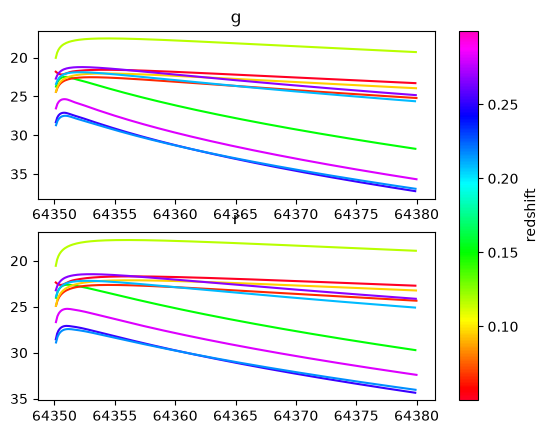

In [293]:
cmap = plt.colormaps['gist_rainbow']
which_param = 'redshift'
def modifier(arr):
    return arr
    # return np.log(arr)
lo, hi = modifier(min(graph_state['source'][which_param])), modifier(max(graph_state['source'][which_param]))
clims = (modifier(graph_state['source'][which_param]) - lo) / (hi - lo)

bands = 'gr'
fig, axs = plt.subplots(len(bands),1)

for b, band in enumerate(bands):
    ax = axs[b]
    for i in range(10):
        # plt.plot(lc['times'],lc['g'])
        lc = lcs['lightcurve'][i]
        ax.plot((np.array(lc['times'][:1000])*u.day), (np.array(lc[band][:1000])* u.nJy).to(u.ABmag, equivalencies=u.spectral()),
               c=cmap(clims[i]))
    ax.set_title(band)
    ax.invert_yaxis()
# plt.axvline(t0)
plt.colorbar(plt.cm.ScalarMappable(norm=mpl.colors.Normalize(lo, hi), cmap=cmap),
              ax=axs, label=which_param)
plt.show()

![](https://content.cld.iop.org/journals/0004-637X/989/2/192/revision2/apjadea3at2_lr.gif)

Alex TODO:
- [ ] Identify time of peak
- [ ] Define pre-peak and post-peak observations up to tmax=15
- [ ] Count pre- and post- peak points above a threshold f

In [280]:
# split for testing purposes, will do array-wise next
def find_t_peak(lc, band):
    ipeak = np.argmax(lc[band])
    tpeak = lc['times'][ipeak]
    return ipeak, tpeak

def find_a1s(lcs, bands=('u', 'g', 'r', 'i', 'z', 'y')):
    a1s = {}
    for band in bands:
        a1 = []
        for i, lc in enumerate(lcs['lightcurve']):
            a1.append(find_t_peak(lc, band)[1] - t0)
        a1s['a1'+band] = a1
    return a1s

In [294]:
a1s = find_a1s(lcs)

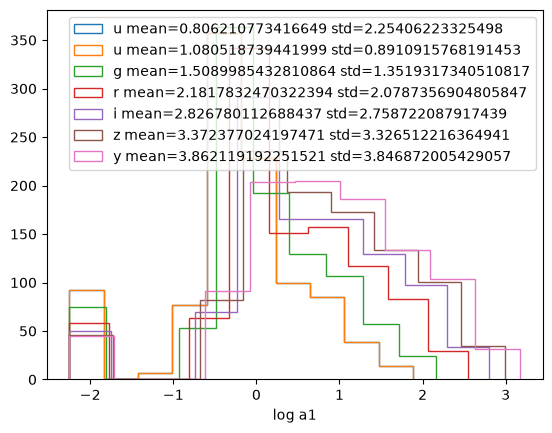

In [314]:
bands = 'ugrizy'
# fig, axs = plt.subplots(len(bands),1)
# which_param = 'kappa'# "redshift" "v_shock" "m_env" "f_rho_m" "radius" "kappa"
for b, band in enumerate(bands):
    # ax = axs[b]
    # plt.hist(np.log(a1s['a1'+band]), histtype='step', label=band+
             # ' mean=' +str(np.exp(np.mean(np.log(a1s['a1'+band]))))+
             # ' std='+str(np.exp(np.std(np.log(a1s['a1'+band])))))
    plt.hist(np.log(a1s['a1'+band]), histtype='step', label=band+
             ' mean=' +str(np.mean(a1s['a1'+band]))+
             ' std='+str(np.std(a1s['a1'+band])))
    # plt.scatter(graph_state['source'][which_param], np.log(a1s['a1'+band]), label=band, s=1)
#     for i in range(10):
#         # plt.plot(lc['times'],lc['g'])
#         lc = lcs['lightcurve'][i]
#         ax.plot((np.array(lc['times'][:1000])*u.day), (np.array(lc[band][:1000])* u.nJy).to(u.ABmag, equivalencies=u.spectral()),
#                c=cmap(clims[i]))
#     ax.set_title(band)
#     ax.invert_yaxis()
# # plt.axvline(t0)
# plt.colorbar(plt.cm.ScalarMappable(norm=mpl.colors.Normalize(lo, hi), cmap=cmap),
#               ax=axs, label=which_param)
plt.xlabel('log a1')
# plt.title(which_param)
plt.legend()
plt.show()

In [73]:
# def get_pre_peak(lc, band):
#     ipeak, tpeak = find_t_peak(lc, band)
#     tpre = lc['times'][:ipeak]
#     fpre = lc[band][:ipeak]
#     print(len(fpre)/len(lc[band]))
#     return tpre, fpre

In [74]:
# get_pre_peak(lc, 'g')

222

In [75]:
# get_pre_peak(lc, 'r')

237

In [ ]:
# def get_post_peak(lc, band, fthresh=0):
    

In [ ]:
# a1 = {'g': sps.normal(7.2, 3.3),
#       'r': sps.normal(7.7, 3.1),
#       'i': sps.normal()}